<a href="https://colab.research.google.com/github/SrishanthGorla/SERAI/blob/main/Threat_to_Control_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Construct the Risk Register records
risk_register_entries = [
    {"Risk ID": "RR-01", "Technique ID": "AML.T0054", "Technique": "LLM Prompt Injection", "Asset": "System Prompt & Orchestrator", "Impact": "High", "Control Type": "Preventive", "Control": "Dual-delimiter boundaries & Llama Guard input filtering", "Owner": "AppSec Lead", "Evidence": "Guardrail unit test passes & CI/CD logs"},
    {"Risk ID": "RR-02", "Technique ID": "AML.T0054", "Technique": "LLM Prompt Injection", "Asset": "System Prompt & Orchestrator", "Impact": "High", "Control Type": "Detective", "Control": "Semantic jailbreak similarity detection in prompt stream", "Owner": "SOC Analyst", "Evidence": "SIEM alert logs & anomalous prompt records"},
    {"Risk ID": "RR-03", "Technique ID": "AML.T0054", "Technique": "LLM Prompt Injection", "Asset": "System Prompt & Orchestrator", "Impact": "High", "Control Type": "Response", "Control": "Session termination & fallback to safe canned string", "Owner": "AI Engineer", "Evidence": "Automated block execution logs"},
    {"Risk ID": "RR-04", "Technique ID": "AML.T0010", "Technique": "ML Supply Chain Compromise", "Asset": "Model Weights & Libraries", "Impact": "Critical", "Control Type": "Preventive", "Control": "Enforce SafeTensors; block raw pickle deserialization", "Owner": "MLSecOps Lead", "Evidence": "Model loader security policy configuration"},
    {"Risk ID": "RR-05", "Technique ID": "AML.T0010", "Technique": "ML Supply Chain Compromise", "Asset": "Model Weights & Libraries", "Impact": "Critical", "Control Type": "Detective", "Control": "Automated SBOM generation and container vulnerability scanning", "Owner": "DevSecOps Lead", "Evidence": "Signed SBOM attestation & Trivy scan reports"},
    {"Risk ID": "RR-06", "Technique ID": "AML.T0010", "Technique": "ML Supply Chain Compromise", "Asset": "Model Weights & Libraries", "Impact": "Critical", "Control Type": "Response", "Control": "Container eviction & rollback to signed model baseline", "Owner": "SRE Lead", "Evidence": "Incident response rollback audit logs"},
    {"Risk ID": "RR-07", "Technique ID": "AML.T0020", "Technique": "Poison Training Data", "Asset": "Vector Knowledge Base", "Impact": "High", "Control Type": "Preventive", "Control": "Cryptographic signatures & multi-party approval on ingestion", "Owner": "Data Steward", "Evidence": "Signed document ingestion git commit history"},
    {"Risk ID": "RR-08", "Technique ID": "AML.T0020", "Technique": "Poison Training Data", "Asset": "Vector Knowledge Base", "Impact": "High", "Control Type": "Detective", "Control": "Embedding distance outlier analysis on newly indexed vectors", "Owner": "ML Engineer", "Evidence": "Vector drift reports & anomaly alert logs"},
    {"Risk ID": "RR-09", "Technique ID": "AML.T0020", "Technique": "Poison Training Data", "Asset": "Vector Knowledge Base", "Impact": "High", "Control Type": "Response", "Control": "Automated snapshot rollback and infected cluster purge", "Owner": "Data Engineer", "Evidence": "Vector database restoration execution logs"},
    {"Risk ID": "RR-10", "Technique ID": "AML.T0043", "Technique": "LLM Data Leakage", "Asset": "Customer Records / Internal Data", "Impact": "High", "Control Type": "Preventive", "Control": "Pre-retrieval document RBAC & automatic PII token masking", "Owner": "Privacy Officer", "Evidence": "Context filter unit tests & masking audits"},
    {"Risk ID": "RR-11", "Technique ID": "AML.T0043", "Technique": "LLM Data Leakage", "Asset": "Customer Records / Internal Data", "Impact": "High", "Control Type": "Detective", "Control": "Streaming regex and entropy inspection on model output", "Owner": "SOC Analyst", "Evidence": "DLP interception alerts & pattern match logs"},
    {"Risk ID": "RR-12", "Technique ID": "AML.T0043", "Technique": "LLM Data Leakage", "Asset": "Customer Records / Internal Data", "Impact": "High", "Control Type": "Response", "Control": "Stream drop, redaction replacement, and session invalidation", "Owner": "AppSec Lead", "Evidence": "Interception audit records & notification tickets"},
    {"Risk ID": "RR-13", "Technique ID": "AML.T0029", "Technique": "Denial of ML Service", "Asset": "Compute Endpoints & Inference API", "Impact": "Medium", "Control Type": "Preventive", "Control": "Token budget quotas, sliding window rate limits, context caps", "Owner": "SRE Lead", "Evidence": "API gateway configuration files & quota manifests"},
    {"Risk ID": "RR-14", "Technique ID": "AML.T0029", "Technique": "Denial of ML Service", "Asset": "Compute Endpoints & Inference API", "Impact": "Medium", "Control Type": "Detective", "Control": "Telemetry monitoring on GPU usage and token burn rate", "Owner": "Cloud Ops Lead", "Evidence": "Grafana telemetry dashboards & metric threshold alerts"},
    {"Risk ID": "RR-15", "Technique ID": "AML.T0029", "Technique": "Denial of ML Service", "Asset": "Compute Endpoints & Inference API", "Impact": "Medium", "Control Type": "Response", "Control": "Dynamic autoscaling and automated malicious IP throttling", "Owner": "SRE Lead", "Evidence": "Autoscaling trigger events & firewall drop records"}
]

df_risk = pd.DataFrame(risk_register_entries)

# Save deliverables
df_risk.to_csv("ai_threat_control_risk_register.csv", index=False)
df_risk.to_html("ai_threat_control_risk_register.html", index=False)
print("Saved 'ai_threat_control_risk_register.csv' and 'ai_threat_control_risk_register.html'")

# Display preview
df_risk[["Risk ID", "Technique", "Control Type", "Owner", "Evidence"]].head(8)

Saved 'ai_threat_control_risk_register.csv' and 'ai_threat_control_risk_register.html'


,Risk ID,Technique,Control Type,Owner,Evidence
0,RR-01,LLM Prompt Injection,Preventive,AppSec Lead,Guardrail unit test passes & CI/CD logs
1,RR-02,LLM Prompt Injection,Detective,SOC Analyst,SIEM alert logs & anomalous prompt records
2,RR-03,LLM Prompt Injection,Response,AI Engineer,Automated block execution logs
3,RR-04,ML Supply Chain Compromise,Preventive,MLSecOps Lead,Model loader security policy configuration
4,RR-05,ML Supply Chain Compromise,Detective,DevSecOps Lead,Signed SBOM attestation & Trivy scan reports
5,RR-06,ML Supply Chain Compromise,Response,SRE Lead,Incident response rollback audit logs
6,RR-07,Poison Training Data,Preventive,Data Steward,Signed document ingestion git commit history
7,RR-08,Poison Training Data,Detective,ML Engineer,Vector drift reports & anomaly alert logs


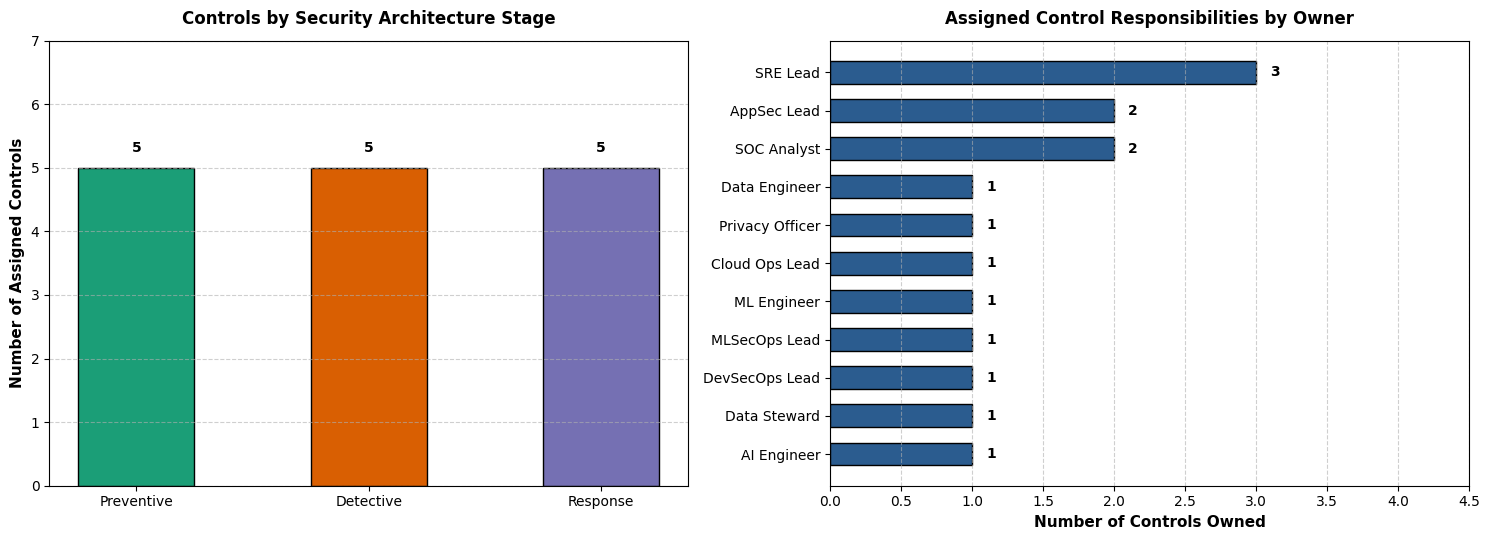

Saved visualization to 'threat_to_control_coverage.png'


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Control Type Distribution (Preventive vs Detective vs Response)
control_counts = df_risk["Control Type"].value_counts()
colors = ["#1b9e77", "#d95f02", "#7570b3"]
bars = axes[0].bar(control_counts.index, control_counts.values, color=colors, edgecolor='black', width=0.5)
axes[0].set_title("Controls by Security Architecture Stage", fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel("Number of Assigned Controls", fontsize=11, fontweight='bold')
axes[0].set_ylim(0, max(control_counts.values) + 2)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.2, int(yval), ha='center', va='bottom', fontweight='bold')

# 2. Control Allocation by Owner
owner_counts = df_risk["Owner"].value_counts().sort_values(ascending=True)
axes[1].barh(owner_counts.index, owner_counts.values, color="#2b5c8f", edgecolor='black', height=0.6)
axes[1].set_title("Assigned Control Responsibilities by Owner", fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel("Number of Controls Owned", fontsize=11, fontweight='bold')
axes[1].set_xlim(0, max(owner_counts.values) + 1.5)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

for index, value in enumerate(owner_counts.values):
    axes[1].text(value + 0.1, index, str(value), va='center', fontweight='bold')

plt.tight_layout()
plt.savefig("threat_to_control_coverage.png", dpi=300)
plt.show()
print("Saved visualization to 'threat_to_control_coverage.png'")